In [1]:
from ete3 import Tree
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['pdf.fonttype'] = 42

plt.rcParams['ps.fonttype'] = 42

plt.rcParams['font.family'] = 'sans-serif'

plt.rcParams['font.sans-serif'] = 'Arial'

def analyze_tree_and_genotypes(tree_file, genotypes_file, title_input,
                               pdf_output="plot.pdf", return_plot_data=False):
    # -----------------------------
    # 1. Load tree
    # -----------------------------
    with open(tree_file, "r") as f:
        newick_tree = f.read().strip()

    tree = Tree(newick_tree, format=1)
    root = tree.get_tree_root()

    # Compute root→leaf distances
    distances_from_root = {}
    for leaf in tree.iter_leaves():
        name = str(leaf)[3:41]
        distances_from_root[name] = root.get_distance(leaf, topology_only=False)

    # -----------------------------
    # 2. Load genotypes
    # -----------------------------
    df = pd.read_csv(genotypes_file, sep="\t")

    dict_mut = {col: [0, 0, 0] for col in df.columns if col != "Site"}

    for col in dict_mut.keys():
        for x in df[col]:
            if x == "H":
                dict_mut[col][0] += 1
            elif x == "R":
                dict_mut[col][1] += 1
            else:
                dict_mut[col][2] += 1

    # -----------------------------
    # 3. Build final variables
    # -----------------------------
    number_mutated_sites   = {k: v[2] for k, v in dict_mut.items()}
    number_reference_sites = {k: v[1] for k, v in dict_mut.items()}
    number_h_sites         = {k: v[0] for k, v in dict_mut.items()}

    x_mut = []
    x_ref = []
    x_h   = []
    y_depth = []

    for k in dict_mut.keys():
        x_mut.append(number_mutated_sites[k])
        x_ref.append(number_reference_sites[k])
        x_h.append(number_h_sites[k])
        y_depth.append(distances_from_root[k])

    # Identify cell with most reference calls
    key = max(number_reference_sites, key=lambda k: number_reference_sites[k])
    print(f"Cell with most references (R): {key}")
    print("Counts (mut, ref, heterozygous):",
          number_mutated_sites[key], number_reference_sites[key], number_h_sites[key])

    # If we only want data, return it now
    if return_plot_data:
        return {
            "x_ref": x_ref,
            "x_mut": x_mut,
            "x_h":   x_h,
            "y":     y_depth,
            "key":   key,
        }

    # -----------------------------
    # 5. Final Plot (normal mode)
    # -----------------------------
    plt.rcParams['font.sans-serif'] = 'Arial'

    plt.figure(figsize=(7, 6))
    plt.plot(x_ref, y_depth, '.', color='#009E73', label="Homozygous reference (RR)", markersize=5)
    plt.plot(x_mut, y_depth, '.', color='#0072B2', label="Homozygous mutated (AA)", markersize=5)
    plt.plot(x_h,  y_depth, '.', color='#D55E00', label="Heterozygous (RA)", markersize=5)

    plt.legend(loc='center right', fontsize=14, markerscale=2.5)
    plt.xlabel("Number of assignments", fontsize=16)
    plt.ylabel("Root distance (subs/site)", fontsize=16)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.xlim(-10, 599)

    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.title(title_input, fontsize=16)
    plt.tight_layout()

    plt.savefig(pdf_output, format="pdf", bbox_inches="tight")
    plt.show()

    return key


Cell with most references (R): Breast_Cancer_3p_LT_TCACGCTTCCCAAGCG-1
Counts (mut, ref, heterozygous): 77 287 96


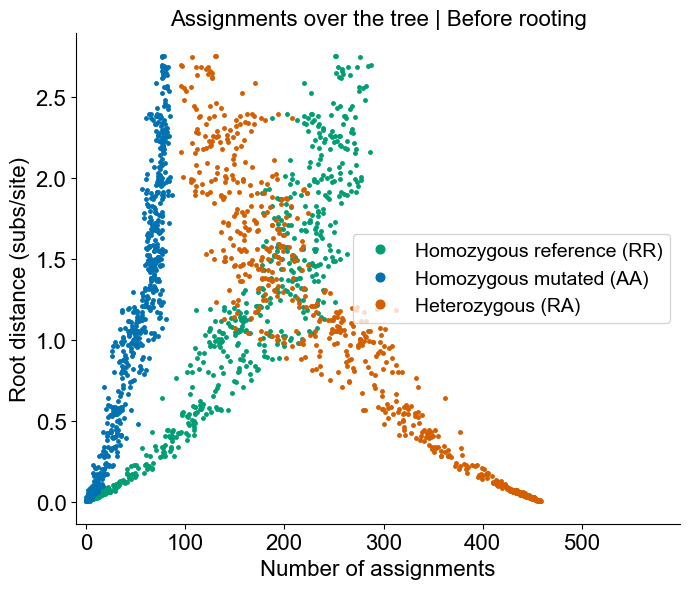

In [2]:
key = analyze_tree_and_genotypes("../fasttree_no_pon", "../genotypes_no_PON.txt", "Assignments over the tree | Before rooting", pdf_output="assignments_plot_bef_rooting.pdf" )

Cell with most references (R): Breast_Cancer_3p_LT_TCACGCTTCCCAAGCG-1
Counts (mut, ref, heterozygous): 77 287 96


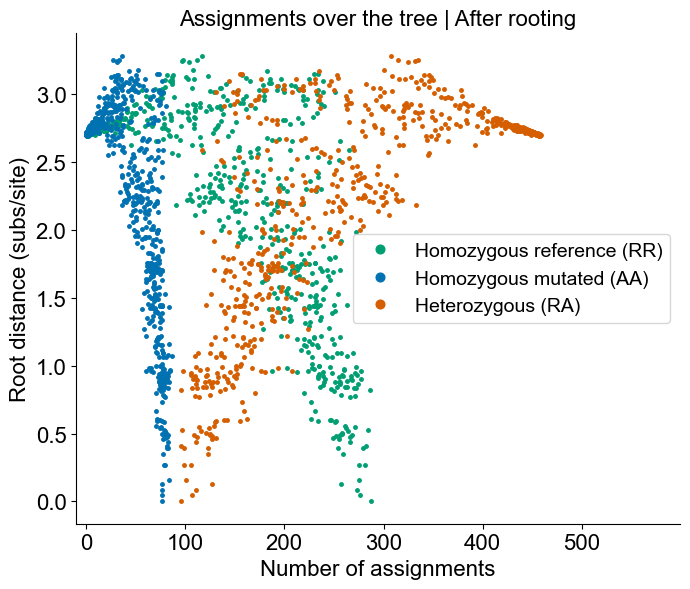

In [3]:
key = analyze_tree_and_genotypes("../rerooted", "../genotypes_no_PON.txt", "Assignments over the tree | After rooting", pdf_output="assignments_plot_after_rooting.pdf" )

Cell with most references (R): Breast_Cancer_3p_LT_TCACGCTTCCCAAGCG-1
Counts (mut, ref, heterozygous): 77 287 96
Cell with most references (R): Breast_Cancer_3p_LT_TCACGCTTCCCAAGCG-1
Counts (mut, ref, heterozygous): 77 287 96


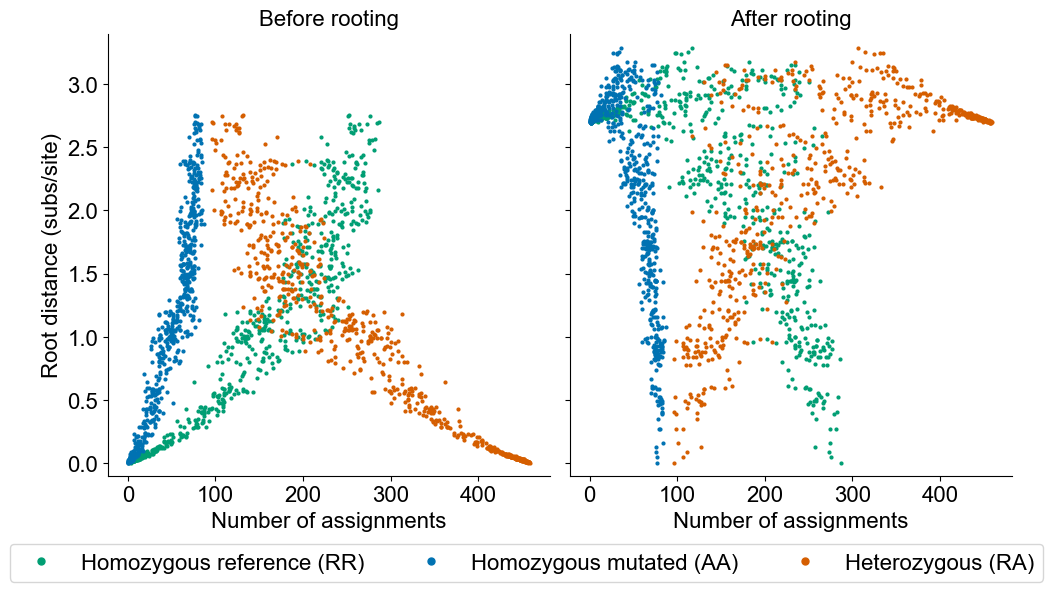

In [8]:
before = analyze_tree_and_genotypes(
    "../fasttree_no_pon",
    "../genotypes_no_PON.txt",
    "Before rooting",
    return_plot_data=True
)

after = analyze_tree_and_genotypes(
    "../rerooted",
    "../genotypes_no_PON.txt",
    "After rooting",
    return_plot_data=True
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)

ax1, ax2 = axes

# ----------------------------------------------------
# BEFORE ROOTING (left subplot)
# ----------------------------------------------------
ax1.plot(before["x_ref"], before["y"], '.', color='#009E73', markersize=4, label="Homozygous reference (RR)")
ax1.plot(before["x_mut"], before["y"], '.', color='#0072B2', markersize=4, label="Homozygous mutated (AA)")
ax1.plot(before["x_h"],   before["y"], '.', color='#D55E00', markersize=4, label="Heterozygous (RA)")

ax1.set_title("Before rooting", fontsize=16)
ax1.set_xlabel("Number of assignments", fontsize=16)
ax1.set_ylabel("Root distance (subs/site)", fontsize=16)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ----------------------------------------------------
# AFTER ROOTING (right subplot)
# ----------------------------------------------------
ax2.plot(after["x_ref"], after["y"], '.', color='#009E73', markersize=4)
ax2.plot(after["x_mut"], after["y"], '.', color='#0072B2', markersize=4)
ax2.plot(after["x_h"],   after["y"], '.', color='#D55E00', markersize=4)

ax2.set_title("After rooting", fontsize=16)
ax2.set_xlabel("Number of assignments", fontsize=16)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-0.1, 3.4)

ax1.tick_params(axis='both', labelsize=16)
ax2.tick_params(axis='both', labelsize=16)



# ----------------------------------------------------
# ONE LEGEND, centered under both plots
# ----------------------------------------------------
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=3, fontsize=16, markerscale=2.5)

plt.tight_layout(rect=[0, 0.08, 1, 1])  # leave space for legend at bottom
plt.savefig("combined_side_by_side.pdf", bbox_inches="tight")
plt.show()
